# Miniproyecto 3: Clasificación de artículos de noticias de la BBC con Transformers


## Objetivo

Desarrollar un modelo de clasificación multi-clase basado en transformers que
identifique la categoría de artículos de noticias de la BBC. 


## 1. Importación de librerías

In [1]:
%pip install -q kagglehub transformers scikit-learn seaborn matplotlib pandas


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [8]:
import os
import random

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support
from transformers import BertTokenizerFast, BertForSequenceClassification, get_linear_schedule_with_warmup
import warnings
import re
warnings.filterwarnings('ignore')

# Semillas para que los resultados sean reproducibles
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Seleccionar GPU si está disponible
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Dispositivo utilizado: {device}")

Dispositivo utilizado: mps


## 2. Carga y exploración de los datos

In [3]:
dataset_dir = kagglehub.dataset_download("jacopoferretti/bbc-articles-dataset")
print(os.listdir(dataset_dir))

csv_file = [f for f in os.listdir(dataset_dir) if f.endswith('.csv')][0]
df = pd.read_csv(os.path.join(dataset_dir, csv_file))

print(df.shape)
df.head()

['archive (2)', 'archive', 'bbc_news_text_complexity_summarization.csv']
(2127, 7)


,text,labels,no_sentences,Flesch Reading Ease Score,Dale-Chall Readability Score,text_rank_summary,lsa_summary
0,Ad sales boost Time Warner profit\n\nQuarterly...,business,26,62.17,9.72,It hopes to increase subscribers by offering t...,Its profits were buoyed by one-off gains which...
1,Dollar gains on Greenspan speech\n\nThe dollar...,business,17,65.56,9.09,The dollar has hit its highest level against t...,"""I think the chairman's taking a much more san..."
2,Yukos unit buyer faces loan claim\n\nThe owner...,business,14,69.21,9.66,The owners of embattled Russian oil giant Yuko...,Yukos' owner Menatep Group says it will ask Ro...
3,High fuel prices hit BA's profits\n\nBritish A...,business,24,62.98,9.86,Looking ahead to its full year results to Marc...,"Rod Eddington, BA's chief executive, said the ..."
4,Pernod takeover talk lifts Domecq\n\nShares in...,business,17,70.63,10.23,Reports in the Wall Street Journal and the Fin...,Shares in UK drinks and food firm Allied Domec...


In [4]:
# Columnas de texto y de categoría (el dataset usa 'text' y 'labels')
TEXT_COL = 'text'
LABEL_COL = 'labels'

df = df[[TEXT_COL, LABEL_COL]].dropna().drop_duplicates(subset=TEXT_COL).reset_index(drop=True)
print(df.shape)
print(df[LABEL_COL].value_counts())

(2127, 2)
labels
sport            505
business         503
politics         403
entertainment    369
tech             347
Name: count, dtype: int64


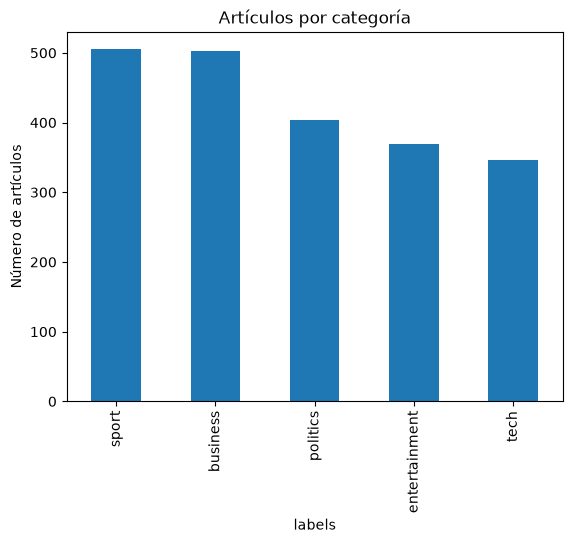

count    2127.000000
mean      384.112835
std       241.399741
min        89.000000
25%       245.000000
50%       331.000000
75%       471.000000
max      4432.000000
Name: text, dtype: float64

In [5]:
df[LABEL_COL].value_counts().plot(kind='bar', title='Artículos por categoría')
plt.ylabel('Número de artículos')
plt.show()

# Longitud de los artículos en palabras (para elegir max_len)
df[TEXT_COL].str.split().str.len().describe()

## 3. Preprocesamiento

1. **Limpieza**: se normalizan espacios y saltos de línea. No se eliminan stopwords, signos ni mayúsculas, porque BERT usa el contexto completo de la oración y su tokenizador ya se encarga de la normalización (`bert-base-uncased` pasa a minúsculas).
2. **Etiquetas**: se codifican las categorías como enteros `0..K-1` (formato requerido por la entropía cruzada).
3. **Tokenización**: WordPiece, agregando `[CLS]` y `[SEP]`, con *padding* y truncamiento a `MAX_LEN` y generando la `attention_mask`.
4. **División** estratificada en entrenamiento (70%), validación (15%) y prueba (15%).

In [6]:
# 70% train, 15% validación, 15% prueba
train_df, resto = train_test_split(df, test_size=0.30, stratify=df[LABEL_COL], random_state=SEED)
val_df, test_df = train_test_split(resto, test_size=0.50, stratify=resto[LABEL_COL], random_state=SEED)
print(f"Datos entrenamiento: {len(train_df)}\nDatos validacion: {len(val_df)} \nDatos prueba: {len(test_df)}")

Datos entrenamiento: 1488
Datos validacion: 319 
Datos prueba: 320


In [9]:
def limpiar_texto(texto):
    # Solo se normalizan espacios y saltos de línea; el resto lo maneja el tokenizador de BERT
    return re.sub(r'\s+', ' ', texto).strip()

df['text_clean'] = df[TEXT_COL].apply(limpiar_texto)

classes = sorted(df[LABEL_COL].unique())
label2id = {c: i for i, c in enumerate(classes)}
id2label = {i: c for c, i in label2id.items()}
df['label_id'] = df[LABEL_COL].map(label2id)
print(label2id)


{'business': 0, 'entertainment': 1, 'politics': 2, 'sport': 3, 'tech': 4}


In [10]:
MODEL_NAME = 'bert-base-uncased'
MAX_LEN = 256   # BERT admite hasta 512; 256 cubre la parte más informativa del artículo y reduce memoria/tiempo
BATCH_SIZE = 16

tokenizer = BertTokenizerFast.from_pretrained(MODEL_NAME)

class BBCDataset(Dataset):
    def __init__(self, texts, labels):
        self.enc = tokenizer(list(texts), truncation=True, padding='max_length',
                             max_length=MAX_LEN, return_tensors='pt')
        self.labels = torch.tensor(list(labels), dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return {'input_ids': self.enc['input_ids'][i],
                'attention_mask': self.enc['attention_mask'][i],
                'labels': self.labels[i]}

train_ds = BBCDataset(train_df['text_clean'], train_df['label_id'])
val_ds = BBCDataset(val_df['text_clean'], val_df['label_id'])
test_ds = BBCDataset(test_df['text_clean'], test_df['label_id'])

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE)

print(tokenizer.convert_ids_to_tokens(train_ds[0]['input_ids'][:20]))

KeyError: 'text_clean'

## 4. Arquitectura

Se usa `BertForSequenceClassification` con `bert-base-uncased`:

- **Por qué BERT**: es un codificador bidireccional; la atención sobre todo el artículo captura el contexto de cada palabra (p. ej. *"bank"* en finanzas vs. otros contextos), algo que las RNN procesan secuencialmente y con peor manejo de dependencias largas. Los artículos de la BBC están en inglés estándar, para el que `bert-base-uncased` fue preentrenado, y el dataset (~2,200 artículos) es pequeño, lo que favorece el *transfer learning* frente a entrenar desde cero.
- **Capa añadida**: sobre la salida del token `[CLS]` (pooled output) el modelo agrega *dropout* (0.1) y una capa lineal `768 → K` (K = número de categorías). Esa capa produce los *logits* de cada clase.
  - El *dropout* regulariza la cabeza de clasificación, que parte de pesos aleatorios, y reduce el sobreajuste con pocos datos.
  - La capa lineal proyecta la representación del artículo al espacio de clases.
- **Softmax + entropía cruzada**: al ser multi-clase de una sola categoría por artículo, softmax convierte los logits en una distribución de probabilidad que suma 1 y se entrena con `CrossEntropyLoss` (que `BertForSequenceClassification` aplica internamente cuando `num_labels > 1`). La predicción es el `argmax`.
- **Fine-tuning completo** con `AdamW`, *learning rate* pequeño (2e-5) y *warmup* lineal, valores recomendados para no destruir el conocimiento preentrenado.

In [10]:
model = BertForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(classes), id2label=id2label, label2id=label2id
).to(device)

print(model.classifier)
print(f"Parámetros entrenables: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 12204.87it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpo

Linear(in_features=768, out_features=5, bias=True)
Parámetros entrenables: 109,486,085


## 5. Entrenamiento

Se entrena 3 épocas (dentro del rango 2 a 5 pedido). Al final de cada época se evalúa en validación y se guarda el mejor modelo según la *accuracy* de validación.

In [11]:
EPOCHS = 3
LR = 2e-5

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)

def evaluate(loader):
    model.eval()
    total_loss, preds, trues = 0.0, [], []
    with torch.no_grad():
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            out = model(**batch)
            total_loss += out.loss.item() * len(batch['labels'])
            preds.extend(out.logits.argmax(dim=-1).cpu().numpy())
            trues.extend(batch['labels'].cpu().numpy())
    return total_loss / len(trues), np.array(preds), np.array(trues)

history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
best_val_acc, best_state = 0.0, None

for epoch in range(EPOCHS):
    model.train()
    running = 0.0
    for batch in train_loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        optimizer.zero_grad()
        loss = model(**batch).loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        running += loss.item() * len(batch['labels'])

    train_loss = running / len(train_ds)
    val_loss, vp, vt = evaluate(val_loader)
    val_acc = accuracy_score(vt, vp)
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    print(f"Época {epoch+1}/{EPOCHS} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | val_acc={val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

model.load_state_dict(best_state)

Época 1/3 | train_loss=0.9998 | val_loss=0.2684 | val_acc=0.9655
Época 2/3 | train_loss=0.1167 | val_loss=0.1317 | val_acc=0.9655
Época 3/3 | train_loss=0.0402 | val_loss=0.0699 | val_acc=0.9812


<All keys matched successfully>

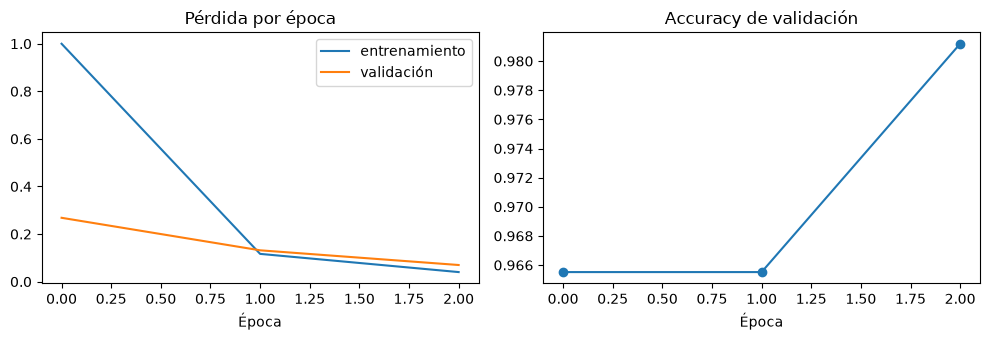

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(history['train_loss'], label='entrenamiento')
ax[0].plot(history['val_loss'], label='validación')
ax[0].set_title('Pérdida por época'); ax[0].set_xlabel('Época'); ax[0].legend()
ax[1].plot(history['val_acc'], marker='o')
ax[1].set_title('Accuracy de validación'); ax[1].set_xlabel('Época')
plt.tight_layout(); plt.show()

## 6. Evaluación en el conjunto de prueba

In [13]:
_, test_preds, test_true = evaluate(test_loader)

acc = accuracy_score(test_true, test_preds)
p_m, r_m, f_m, _ = precision_recall_fscore_support(test_true, test_preds, average='macro')
p_w, r_w, f_w, _ = precision_recall_fscore_support(test_true, test_preds, average='weighted')

print(f"Accuracy: {acc:.4f}")
print(f"Macro    -> precisión: {p_m:.4f} | recall: {r_m:.4f} | F1: {f_m:.4f}")
print(f"Weighted -> precisión: {p_w:.4f} | recall: {r_w:.4f} | F1: {f_w:.4f}")

Accuracy: 0.9844
Macro    -> precisión: 0.9847 | recall: 0.9838 | F1: 0.9841
Weighted -> precisión: 0.9845 | recall: 0.9844 | F1: 0.9844


In [14]:
print(classification_report(test_true, test_preds, target_names=classes, digits=4))

               precision    recall  f1-score   support

     business     0.9737    0.9737    0.9737        76
entertainment     0.9821    1.0000    0.9910        55
     politics     0.9677    0.9836    0.9756        61
        sport     1.0000    1.0000    1.0000        76
         tech     1.0000    0.9615    0.9804        52

     accuracy                         0.9844       320
    macro avg     0.9847    0.9838    0.9841       320
 weighted avg     0.9845    0.9844    0.9844       320



In [15]:
# Métricas por categoría, ordenadas de mejor a peor F1
p, r, f, s = precision_recall_fscore_support(test_true, test_preds, labels=range(len(classes)))
per_class = pd.DataFrame({'categoria': classes, 'precision': p, 'recall': r, 'f1': f, 'soporte': s}).sort_values('f1', ascending=False)
display(per_class.round(4))
print(f"Mejor categoría: {per_class.iloc[0]['categoria']} (F1={per_class.iloc[0]['f1']:.4f})")
print(f"Peor categoría:  {per_class.iloc[-1]['categoria']} (F1={per_class.iloc[-1]['f1']:.4f})")

,categoria,precision,recall,f1,soporte
3,sport,1.0000,1.0000,1.0000,76
1,entertainment,0.9821,1.0000,0.9910,55
4,tech,1.0000,0.9615,0.9804,52
2,politics,0.9677,0.9836,0.9756,61
0,business,0.9737,0.9737,0.9737,76


Mejor categoría: sport (F1=1.0000)
Peor categoría:  business (F1=0.9737)


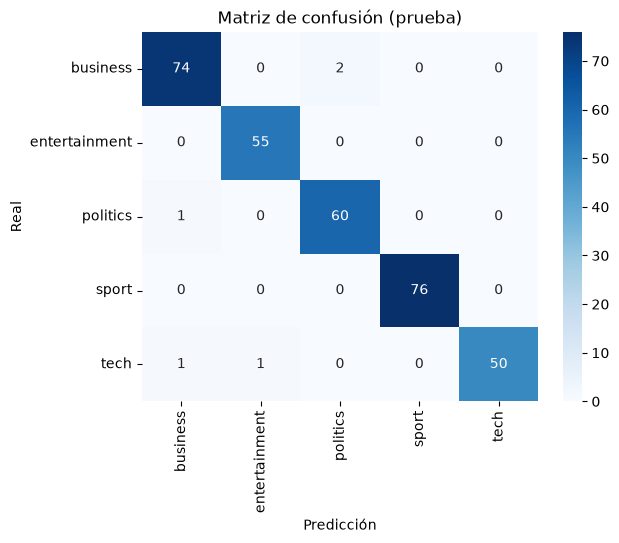

In [16]:
cm = confusion_matrix(test_true, test_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.xlabel('Predicción'); plt.ylabel('Real'); plt.title('Matriz de confusión (prueba)')
plt.show()

In [17]:
# Ejemplos mal clasificados
errors = test_df.reset_index(drop=True)[test_preds != test_true].copy()
errors['predicha'] = [id2label[i] for i in test_preds[test_preds != test_true]]
errors['real'] = errors[LABEL_COL]
errors['texto'] = errors['text_clean'].str[:200]
errors[['real', 'predicha', 'texto']]

,real,predicha,texto
23,business,politics,Golden rule 'intact' says ex-aide Chancellor G...
126,business,politics,Call to save manufacturing jobs The Trades Uni...
185,tech,business,Who do you think you are? The real danger is n...
239,politics,business,UK firms 'embracing e-commerce' UK firms are e...
307,tech,entertainment,Web radio takes Spanish rap global Spin the ra...


## 7. Análisis de resultados

*Completar después de ejecutar el notebook con los números obtenidos:*

- **Desempeño global**: accuracy, precisión, recall y F1 (macro y ponderado) en prueba.
- **Mejores categorías**: cuáles tienen mayor F1 y por qué (vocabulario muy distintivo, p. ej. deportes).
- **Peores categorías**: cuáles tienen menor F1 y con qué clases se confunden según la matriz de confusión (p. ej. política vs. negocios, o tecnología vs. negocios, por solapamiento temático).
- **Limitaciones y mejoras**: truncamiento a 256 tokens, tamaño del dataset, posibilidad de probar RoBERTa, más épocas o `MAX_LEN` mayor.